In [27]:
!pip install torchvision torch numpy matplotlib

In [28]:
# import necessary libraries
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import dataloader
import matplotlib.pyplot as plt
import numpy as np

In [29]:
# encoder class, which maps imput data to the latent space
class Encoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, latent_dim):
        """
        Initialize the Encoder class.

        Args:

        input_dim: dimension of the input data
        hidden_dim: dimension of the hidden layer
        latent_dim: dimension of the latent space
        """
        super(Encoder, self).__init__()
        
        # define fully connected layers
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)
        
        # define the forward pass through the Encoder
    def forward(self, x):
    
        """
        Define the forward pass through the Encoder.

        Args:

        x: input data

        Returns:
        mu: the mean of the latent space.
        logvar: the log variance of the latent space.
            """
        # apply Relu activation to hidden layer
        h = torch.relu(self.fc1(x))
        # calculate Mu and Logvar
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)

        return mu, logvar
        
    

In [30]:
import torch
import torch.nn as nn

class Decoder(nn.Module):

    def __init__(self, latent_dim, hidden_dim, output_dim):
        super().__init__()

        # Define fully connected layers
        self.fc1 = nn.Linear(latent_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, z):

        # Hidden layer with ReLU activation
        h = torch.relu(self.fc1(z))

        # Output layer with Sigmoid activation
        x_hat = torch.sigmoid(self.fc2(h))

        return x_hat

In [31]:
#Define the variational autoencoder VAE class
class VAE(nn.Module):
    def __init__(self, input_dim, hidden_dim, latent_dim):
        super().__init__()

        # Define Encoder and Decoder
        self.encoder = Encoder(input_dim, hidden_dim, latent_dim)
        self.decoder = Decoder(latent_dim, hidden_dim, input_dim)

    def forward(self, x):
        # Encode input into latent space
        mu, logvar = self.encoder(x)

        # Sample from latent space using reparameterization trick
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        z = mu + eps * std

        # Decode latent vector into reconstructed output
        x_hat = self.decoder(z)

        return x_hat, mu, logvar


In [32]:
def loss_function(x, x_hat, mu, logvar):
  """
  Define the loss functoin for the VAE

  Args:
  x: input data
  x_hat: the reconstructed output data.
  mu: the mean of the latent space.
  logvar: the log variance of the latent space.

  Returns:
  loss: the VAE loss.
  """

  #Calculate Binary Cross-Entropy loss
  BCE = nn.functional.binary_cross_entropy(x_hat, x, reduction='sum')

  #Calculate KL = kullback-leibler divergence loss
  KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())

  return BCE + KLD


In [33]:
input_dim = 784
hidden_dim = 400
latent_dim = 20
lr = 1e-3
batch_size = 128
epochs = 10


#Data loader
transform = transforms.Compose([transforms.ToTensor(), transforms.Lambda(lambda x: x.view(-1))])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
train_loader = dataloader.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

In [34]:
#model, optimizer
vae = VAE(input_dim, hidden_dim, latent_dim)
optimizer = optim.Adam(vae.parameters(), lr=lr)

#Training loop
for epoch in range(epochs):
  train_loss = 0
  for x, _ in train_loader:
    x = x.view(-1, input_dim)
    optimizer.zero_grad()
    x_hat, mu, logvar = vae(x)
    loss = loss_function(x, x_hat, mu, logvar)
    loss.backward()
    optimizer.step()
    train_loss += loss.item()

  print(f"Epoch {epoch+1}, Loss:{train_loss/len(train_loader.dataset)}")



Epoch 1, Loss:164.28235247395833
Epoch 2, Loss:121.418659765625
Epoch 3, Loss:114.74578198242187
Epoch 4, Loss:111.64949959309895
Epoch 5, Loss:109.89941578776042
Epoch 6, Loss:108.75054580078125
Epoch 7, Loss:107.94123237304687
Epoch 8, Loss:107.26141233723958
Epoch 9, Loss:106.7008251953125
Epoch 10, Loss:106.23566368815104


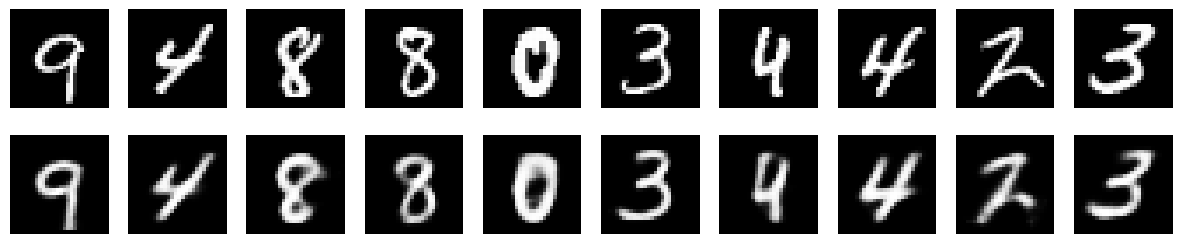

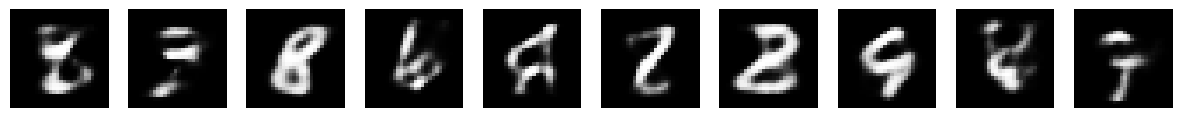

In [35]:
vae.eval()

# Reconstructing of the input data
with torch.no_grad():

  x, _ = next(iter(train_loader)) #(-1, 784)

  x = x.view(-1, input_dim)

  x_hat, _, _ = vae(x)

  x = x.view(-1, 28, 28) #(28 * 28)

  x_hat = x_hat.view(-1, 28, 28)

  fig, axs = plt.subplots(2, 10, figsize= (15, 3))

  for i in range(10):
    axs[0, i].imshow(x[i].cpu().numpy(), cmap='gray')
    axs[1, i].imshow(x_hat[i].cpu().numpy(), cmap='gray')
    axs[0, i].axis('off')
    axs[1, i].axis('off')

  plt.show()






# Visualizing new Generated data

# Generative AI PART
with torch.no_grad():
  z = torch.randn(10, latent_dim)

  sample = vae.decoder(z)
  sample = sample.view(-1, 28, 28)

  fig, axs = plt.subplots(1, 10, figsize= (15, 3))

  for i in range(10):

    axs[i].imshow(sample[i].cpu().numpy(), cmap = 'gray')
    axs[i].axis('off')
  plt.show()


